### Imports

In [ ]:
# Uncomment to install necessary packages:
!pip install rispy bibtexparser

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for bibtexparser: filename=bibtexparser-1.4.3-py3-none-any.whl size=43549 sha256=61dc7b24a87320c1bc042fbb7833d2036097c3912afd24208f57881e95a9a333
  Stored in directory: /root/.cache/pip/wheels/16/fb/76/306387739cf9d53b1c39b0c8aadbbb17dc05f256756d8fd915
Successfully built bibtexparser


In [ ]:
import pandas as pd
from io import StringIO
import bibtexparser
import rispy
import os

#from google.colab import files
#uploaded = files.upload()

### Auxiliary Functions

In [ ]:
def bib_entries_to_df(entries):
    records = []
    for entry in entries:
        record = {
            "Title": entry.get("title", "").strip(),
            "Authors": entry.get("author", "").strip(),
            "Year": int(entry.get("year", "0")[:4]) if "year" in entry else None,
            "Abstract": entry.get("abstract", "").strip(),
            "Source": entry.get("ID", ""),
            "DOI": entry.get("doi", ""),
            "Source title": entry.get("journal", ""),
            "Journal": entry.get("journal", ""),
            "Book title": entry.get("booktitle", ""),
            "Author Keywords": entry.get("keywords", "")
        }
        records.append(record)
    return pd.DataFrame(records)


### Load Data

Please make sure you have your files loaded in the session, and review the name of the files accordingly.

In [ ]:
base_path = ""
files = {
    "acm_journals": os.path.join(base_path, "acm_journals.bib"),
    "acm_proceedings": os.path.join(base_path, "acm_proceedings.bib"),
    "ieexplore": os.path.join(base_path, "ieexplore.csv"),
    "scopus": os.path.join(base_path, "scopus.csv"),
    "scopus_ris": os.path.join(base_path, "scopus.ris"),
}

In [ ]:
with open(files["acm_journals"], "r", encoding="utf-8") as bibtex_file:
    bib_database_journals = bibtexparser.load(bibtex_file)
    bib_database_journals = bib_entries_to_df(bib_database_journals.entries)
    bib_database_journals = bib_database_journals[bib_database_journals["Year"] >= 2020]
    bib_database_journals = bib_database_journals.drop("Book title", axis=1)
    # merged_data.append(bib_entries_to_df(bib_database.entries))

# Note: books are to be excluded, hence the commented code.
#with open(files["acm_proceedings"], "r", encoding="utf-8") as bibtex_file:
#    bib_database_proceedings = bibtexparser.load(bibtex_file)
#    bib_database_proceedings = bib_entries_to_df(bib_database_proceedings.entries)
#    # merged_data.append(bib_entries_to_df(bib_database.entries))

In [ ]:
print(len(bib_database_journals))
bib_database_journals.sample(2)


243


,Title,Authors,Year,Abstract,Source,DOI,Source title,Journal,Author Keywords
209,On the Relationship between Explanation and Re...,"Li, Lei and Zhang, Yongfeng and Chen, Li",2023,Explaining to users why some items are recomme...,10.1145/3569423,10.1145/3569423,ACM Trans. Intell. Syst. Technol.,ACM Trans. Intell. Syst. Technol.,"Explainable recommendation, explanation rankin..."
190,Personalized Prompt Learning for Explainable R...,"Li, Lei and Zhang, Yongfeng and Chen, Li",2023,Providing user-understandable explanations to ...,10.1145/3580488,10.1145/3580488,ACM Trans. Inf. Syst.,ACM Trans. Inf. Syst.,"Explainable recommendation, Transformer, pre-t..."


In [ ]:
scopus_df = pd.read_csv(files["scopus"])
ieexplore_df = pd.read_csv(files["ieexplore"])

In [ ]:
print(len(scopus_df))
print(scopus_df.columns)
scopus_df = scopus_df[scopus_df["Year"] >= 2020]
scopus_df.sample(2)

262
Index(['Authors', 'Author full names', 'Author(s) ID', 'Title', 'Year',
       'Source title', 'Volume', 'Issue', 'Art. No.', 'Page start', 'Page end',
       'Page count', 'Cited by', 'DOI', 'Link', 'Abstract', 'Author Keywords',
       'Publisher', 'Document Type', 'Publication Stage', 'Open Access',
       'Source', 'EID'],
      dtype='object')


,Authors,Author full names,Author(s) ID,Title,Year,Source title,Volume,Issue,Art. No.,Page start,...,DOI,Link,Abstract,Author Keywords,Publisher,Document Type,Publication Stage,Open Access,Source,EID
197,Pospelova N.; Tarasova A.; Subbotina N.; Korol...,"Pospelova, Nadezda (57136740000); Tarasova, Ai...",57136740000; 56069520300; 57136582000; 5721989...,Explainable Artificial Intelligence and Natura...,2024,Fusion: Practice and Applications,14,2,NaN,146.0,...,10.54216/FPA.140212,https://www.scopus.com/inward/record.uri?eid=2...,Deceptive content recognition in social media ...,BERT; Explainable Artificial Intelligence; Nat...,American Scientific Publishing Group (ASPG),Article,Final,NaN,Scopus,2-s2.0-85186230970
227,Li Y.; Liu S.; Wu C.; Xi X.; Cao G.; Cao W.,"Li, Yan (59070036100); Liu, Shasha (5746562510...",59070036100; 57465625100; 57285827500; 5746562...,DCFG: Discovering Directional CounterFactual G...,2021,Proceedings - 2021 IEEE International Conferen...,NaN,NaN,NaN,972.0,...,10.1109/BIBM52615.2021.9669770,https://www.scopus.com/inward/record.uri?eid=2...,While Deep Neural Networks (DNNs) are achievin...,Black-box Models; Directional CounterFactual G...,Institute of Electrical and Electronics Engine...,Conference paper,Final,NaN,Scopus,2-s2.0-85125181377


In [ ]:
print(len(ieexplore_df))
print(ieexplore_df.columns)
ieexplore_df.columns = [
    'Title', 'Authors', 'Author Affiliations', 'Source title',
    'Date Added To Xplore', 'Year', 'Volume', 'Issue',
    'Start Page', 'End Page', 'Abstract', 'ISSN', 'ISBNs', 'DOI',
    'Funding Information', 'PDF Link', 'Author Keywords', 'IEEE Terms',
    'Mesh_Terms', 'Article Citation Count', 'Patent Citation Count',
    'Reference Count', 'License', 'Online Date', 'Issue Date',
    'Meeting Date', 'Publisher', 'Document Identifier'
]
ieexplore_df = ieexplore_df[ieexplore_df["Year"] >= 2020]
ieexplore_df.sample(2)

248
Index(['Document Title', 'Authors', 'Author Affiliations', 'Publication Title',
       'Date Added To Xplore', 'Publication Year', 'Volume', 'Issue',
       'Start Page', 'End Page', 'Abstract', 'ISSN', 'ISBNs', 'DOI',
       'Funding Information', 'PDF Link', 'Author Keywords', 'IEEE Terms',
       'Mesh_Terms', 'Article Citation Count', 'Patent Citation Count',
       'Reference Count', 'License', 'Online Date', 'Issue Date',
       'Meeting Date', 'Publisher', 'Document Identifier'],
      dtype='object')


,Title,Authors,Author Affiliations,Source title,Date Added To Xplore,Year,Volume,Issue,Start Page,End Page,...,Mesh_Terms,Article Citation Count,Patent Citation Count,Reference Count,License,Online Date,Issue Date,Meeting Date,Publisher,Document Identifier
221,CVSS-BERT: Explainable Natural Language Proces...,M. R. Shahid; H. Debar,"SAMOVAR, Télécom SudParis, Institut Polytechni...",2021 20th IEEE International Conference on Mac...,25 Jan 2022,2021,NaN,NaN,1600,1607,...,NaN,32.0,NaN,21.0,IEEE,25 Jan 2022,NaN,NaN,IEEE,IEEE Conferences
133,Image Captioning for Coronary Artery Disease D...,B. Magalhães; J. Pedrosa; F. Renna; H. Paredes...,"INESC TEC, Porto, Portugal; FEUP, Porto, Portu...",2024 IEEE International Conference on Bioinfor...,10 Jan 2025,2024,NaN,NaN,5302,5308,...,NaN,NaN,NaN,20.0,IEEE,10 Jan 2025,NaN,NaN,IEEE,IEEE Conferences


In [ ]:
#with open(files["scopus_ris"], "r", encoding="utf-8") as ris_file:
#    entries = rispy.load(ris_file)
#    ris_df = pd.DataFrame([{
#        "title": entry.get("title", "").strip(),
#        "authors": ", ".join(entry.get("authors", [])),
#        "year": entry.get("year"),
#        "abstract": entry.get("abstract", "").strip(),
#        "source": "scopus_ris",
#        "doi": entry.get("doi", ""),
#        "journal": entry.get("journal", ""),
#        "booktitle": entry.get("booktitle", "")
#    } for entry in entries])
#    merged_data.append(ris_df)

In [ ]:
cols_to_keep = ["Title", "Authors", "Source title", "Abstract", "DOI", "Year", "Author Keywords"]

dfs = [
    scopus_df[cols_to_keep],
    ieexplore_df[cols_to_keep],
    bib_database_journals[cols_to_keep]
]

merged_data = pd.concat(dfs, ignore_index=True)
merged_data.sample(2)

,Title,Authors,Source title,Abstract,DOI,Year,Author Keywords
398,Fine-Grained Multilingual Hate Speech Detectio...,J. A. Siddiqui; S. S. Yuhaniz; G. M. Shaikh; S...,IEEE Access,The detection of hate speech on online platfor...,10.1109/ACCESS.2024.3470901,2024,Deep learning;explainable AI;hate speech;large...
509,Toward Trustworthy Artificial Intelligence (TA...,"chander, Bhanu and John, Chinju and Warrier, L...",ACM Comput. Surv.,"From the innovation, Artificial Intelligence (...",10.1145/3675392,2025,"Artificial intelligence, machine learning, dee..."


In [ ]:
merged_data.to_csv("initial_papers_list_not_treated.csv", index=False)

### Papers Analysis - Inclusion & Exclusion Criteria

In [ ]:
merged_data = pd.read_csv("initial_papers_list_not_treated.csv")
merged_data.sample(2)

,Title,Authors,Source title,Abstract,DOI,Year,Author Keywords
680,Dual-objective fine-tuning of BERT for entity ...,"Peeters, Ralph and Bizer, Christian",Proc. VLDB Endow.,An increasing number of data providers have ad...,10.14778/3467861.3467878,2021,NaN
358,Deep Emotion Analysis: “Enhancing Emotion clas...,P. Mokshit; P. S. Prasad; N. S. Reddy; T. Singh,2024 15th International Conference on Computin...,"In the era of digital technology, it becomes v...",10.1109/ICCCNT61001.2024.10723323,2024,BERT;Emotion Classification;XAI tools;Transfor...


In [ ]:
print("Total number of extracted papers:", len(merged_data))

Total number of extracted papers: 751


In [ ]:
merged_data["Year"].value_counts()

,count
Year,
2024,333
2025,197
2023,119
2022,50
2021,41
2020,11


Finding and counting duplicates:

In [ ]:
num_duplicates = 0
num_duplicates += len(merged_data) - len(merged_data.drop_duplicates())

merged_data = merged_data.drop_duplicates()

print("Number of duplicates so far:", num_duplicates)

Number of duplicates so far: 0


In [ ]:
# Checking by DOI, Title and Year:
num_duplicates += len(merged_data) - len(merged_data.drop_duplicates(subset=["DOI", "Title", "Year"]))
merged_data = merged_data.drop_duplicates(subset=["DOI", "Title", "Year"])

print("Number of duplicates so far:", num_duplicates)

Number of duplicates so far: 57


In [ ]:
# Checking by Title and Year:
num_duplicates += len(merged_data) - len(merged_data.drop_duplicates(subset=["Title", "Year"]))
merged_data = merged_data.drop_duplicates(subset=["Title", "Year"])

print("Number of duplicates so far:", num_duplicates)

Number of duplicates so far: 59


In [ ]:
print("Total number of remaining papers:", len(merged_data))

Total number of remaining papers: 692


Removing publications that are not ranked Q1 or Q2:

In [ ]:
num_distinct_publications = merged_data["Source title"].nunique()
print("There are a total of", num_distinct_publications, "different publications in this dataset.")

There are a total of 374 different publications in this dataset.


In [ ]:
merged_data["Source title"].value_counts()

,count
Source title,
Proc. ACM Hum.-Comput. Interact.,28
J. Mach. Learn. Res.,26
IEEE Access,25
ACM Trans. Inf. Syst.,21
ACM Trans. Softw. Eng. Methodol.,20
...,...
"Proceedings - 2023 IEEE Visualization Conference - Short Papers, VIS 2023",1
"IEEE International Conference on Data Mining Workshops, ICDMW",1
Information Processing and Management,1


In [ ]:
merged_data.to_csv("papers_for_screening.csv")

In [ ]:
import pandas as pd

merged_data = pd.read_csv("papers_for_screening.csv")
merged_data.drop("Unnamed: 0", axis=1, inplace=True)
merged_data.sample()

,Title,Authors,Source title,Abstract,DOI,Year,Author Keywords
520,The Explanation That Hits Home: The Characteri...,"Ferguson, Sharon and Aoyagui, Paula Akemi and ...",Proc. ACM Hum.-Comput. Interact.,Human-AI collaborative decision-making can ach...,10.1145/3687056,2024,"collaborative decision-making, explainable ai,..."


In [ ]:
"""
Excluded:
International Journal of Intelligent Engineering and Systems, Tropical Medicine and Infectious Disease, Diagnostics,
Nature Communications, Journal of Theoretical and Applied Information Technology, Optics and Laser Technology, Expert Systems,
Viruses, Depression and Anxiety, Arthroplasty Today, Telematics and Informatics, Applied Sciences (Switzerland),
Cell Reports Medicine, Procedia Computer Science, Statistics, Optimization and Information Computing,
IEEE Communications Magazine, Renewable Energy, AI (Switzerland),  International Urology and Nephrology,
Journal of Biomedical Informatics, Social Science Computer Review, International Journal of Speech Technology,
Journal of Medical Internet Research, Solar Energy, Nature Communications, Journal of Medical and Biological Engineering,
Future Internet, Communications Chemistry, Machine Learning, Journal of Medical Imaging, Health Information Science and Systems,
Cognitive Science, JMIR AI, International Journal of Information Engineering and Electronic Business,
Proceedings of the Annual Hawaii International Conference on System Sciences,International Journal of Information and Communication Technology,
Medical Physics, International Conference on Information and Knowledge Management, Proceedings,
World Journal of English Language, Engineering Applications of Artificial Intelligence,
2025 8th International Conference on Electronics, Materials Engineering and Nano-Technology, IEMENTech 2025,
Quantum Machine Intelligence, eClinicalMedicine, 2025 International Conference on Electrical, Computer and Communication Engineering, ECCE 2025,
Proceedings - Annual Reliability and Maintainability Symposium, Artificial Intelligence in Medicine,
2025 International Conference on Emerging Smart Computing and Informatics, ESCI 2025, Progress in Biomedical Optics and Imaging - Proceedings of SPIE,
Atmospheric Environment, Proceedings of the 2024 11th International Conference on Networking, Systems and Security, NSysS 2024,
Journal of Chemical Information and Modeling, International Journal of Informatics and Communication Technology,
Journal of Neuroscience Methods, 2025 5th International Conference on Advanced Research in Computing: Converging Horizons: Uniting Disciplines in Computing Research through AI Innovation, ICARC 2025 - Proceedings,
Engineering Structures, JMIR Public Health and Surveillance, 3rd International Conference on Integrated Circuits and Communication Systems, ICICACS 2025,
Proceedings - 2024 IEEE Evaluation and Beyond - Methodological Approaches for Visualization, BELIV 2024,
PLoS Computational Biology, Society of Petroleum Engineers - SPE International Health, Safety, Environment and Sustainability Conference and Exhibition, HSE 2024,
ICES Journal of Marine Science, Cognitive Systems Research, Decision, IEEE Signal Processing Magazine,
Proceedings of 5th International Conference on IoT Based Control Networks and Intelligent Systems, ICICNIS 2024,
eBioMedicine, International Journal of Information Management Data Insights, Computers and Security,
Frontiers in Medicine, Frontiers in Psychiatry, 2024 IEEE 3rd World Conference on Applied Intelligence and Computing, AIC 2024,
Proceedings - International Conference on Image Processing, ICIP, 2024 IEEE Conference on Computing Applications and Systems, COMPAS 2024,
Proceedings - 2024 IEEE/ACM International Conference on Big Data Computing, Applications and Technologies, BDCAT 2024,
2024 15th International Conference on Computing Communication and Networking Technologies, ICCCNT 2024,
Proceedings of the International Joint Conference on Neural Networks,
2024 IEEE International Conference on Interdisciplinary Approaches in Technology and Management for Social Innovation, IATMSI 2024,
ISPCE-AS 2024 - IEEE International Symposium on Product Compliance Engineering-Asia 2024,
Proceedings of the 2024 IEEE 6th Eurasia Conference on Biomedical Engineering, Healthcare and Sustainability, ECBIOS 2024,
Proceedings of the 2024 IEEE International Conference on Cyber Security and Resilience, CSR 2024,
Proceedings - 2024 25th International Conference on Digital Image Computing: Techniques and Applications, DICTA 2024,
Telecommunications Policy, 2024 6th International Conference on Advancements in Computing, ICAC 2024,
2024 17th International Conference on Security of Information and Networks, SIN 2024,
Proceedings - 32nd IEEE International Requirements Engineering Conference Workshops, REW 2024,
Computer Methods and Programs in Biomedicine Update, 2024 International Conference on Knowledge Engineering and Communication Systems, ICKECS 2024,
Proceedings of the IEEE 3rd International Conference on Problems of Informatics, Electronics and Radio Engineering, PIERE 2024,
ICCC 2024 - IEEE 11th International Conference on Computational Cybernetics and Cyber-Medical Systems, Proceedings,
2024 International Conference on Innovations in Science, Engineering and Technology: Innovative Technologies for Global Solutions, ICISET 2024,
Journal of Property Investment and Finance, Electronic Journal of e-Learning,
2024 International Conference on Intelligent Systems for Cybersecurity, ISCS 2024,
EMNLP 2024 - 2024 Conference on Empirical Methods in Natural Language Processing, Proceedings of System Demonstrations,
American Journal of Emergency Medicine, International IEEE Conference  proceedings, IS,
International Journal of Human-Computer Interaction, 2024 IEEE/ACIS 24th International Conference on Computer and Information Science, ICIS 2024 - Proceedings,
Proceedings - International Conference on Software Engineering, Proceedings - 2024 International Conference on Machine Learning and Applications, ICMLA 2024,
2024 International Conference on Frontiers of Information Technology, FIT 2024, 2024 4th International Conference on Intelligent Technologies, CONIT 2024,
International Journal of Cognitive Computing in Engineering, Current Biology, IEEE Computer Society Conference on Computer Vision and Pattern Recognition Workshops,
Entropy, Proceedings - 2023 IEEE International Conference on Big Data, BigData 2023, Proceedings - 2022 IEEE/CVF Winter Conference on Applications of Computer Vision, WACV 2022,
Proceedings of SPIE - The International Society for Optical Engineering, Information Processing and Management, 2023 IEEE Pune Section International Conference, PuneCon 2023,
Scientific African, International Journal of Computer Assisted Radiology and Surgery, Frontiers in Systems Neuroscience, Proceedings - IEEE International Conference on Data Mining, ICDM,
Proceedings - IEIT 2023: 2023 International Conference on Electrical and Information Technology, Proceedings - 2021 IEEE International Conference on Bioinformatics and Biomedicine, BIBM 2021,
Proceedings of the 2023 IEEE International Conference on Behavioural and Social Computing, BESC 2023, ACM-BCB 2023 - 14th ACM Conference on Bioinformatics, Computational Biology, and Health Informatics,
Journal of Risk and Financial Management, Proceedings of the 38th Conference on Uncertainty in Artificial Intelligence, UAI 2022, IEEE Journal of Biomedical and Health Informatics,
International Journal on Recent and Innovation Trends in Computing and Communication, SIGIR 2023 - Proceedings of the 46th International ACM SIGIR Conference on Research and Development in Information Retrieval,
NAACL-HLT 2021 - 2021 Conference of the North American Chapter of the Association for Computational Linguistics: Human Language Technologies, Proceedings of the Conference,
Wireless Personal Communications, Conference Proceedings - IEEE International Conference on Systems, Man and Cybernetics, Scientometrics, 35th AAAI Conference on Artificial Intelligence, AAAI 2021,
Physics in Medicine and Biology, 2023 26th International Conference on Computer and Information Technology, ICCIT 2023, ICDL-EpiRob 2020 - 10th IEEE International Conference on Development and Learning and Epigenetic Robotics,
SemEval 2021 - 15th International Workshop on Semantic Evaluation, Proceedings of the Workshop, 2023 IEEE 13th Annual Computing and Communication Workshop and Conference (CCWC),
2024 8th International Artificial Intelligence and Data Processing Symposium (IDAP), 2025 International Conference on Data Science and Business Systems (ICDSBS),
2025 International Conference on Industrial Engineering, Applications and Manufacturing (ICIEAM), 2024 Innovations in Intelligent Systems and Applications Conference (ASYU),
2024 IEEE International Conference on Engineering, Technology, and Innovation (ICE/ITMC), 2023 IEEE Visualization and Visual Analytics (VIS),
2025 International Conference on Artificial Intelligence and Data Engineering (AIDE), 2024 IEEE Symposium on Visual Languages and Human-Centric Computing (VL/HCC),
2024 International Conference on Content-Based Multimedia Indexing (CBMI), 2024 IEEE International Multi-Conference on Engineering, Computer and Information Sciences (SIBIRCON),
2024 2nd DMIHER International Conference on Artificial Intelligence in Healthcare, Education and Industry (IDICAIEI), 2024 IEEE International Conference on Big Data (BigData),
2024 2nd International Conference on Foundation and Large Language Models (FLLM), 2025 IEEE 15th Annual Computing and Communication Workshop and Conference (CCWC),
2024 11th International Conference on Social Networks Analysis, Management and Security (SNAMS), 2023 IEEE Asia-Pacific Conference on Computer Science and Data Engineering (CSDE),
2024 15th International Conference on Computing Communication and Networking Technologies (ICCCNT), 2025 8th International Conference on Advanced Algorithms and Control Engineering (ICAACE),
2024 6th International Conference on Process Mining (ICPM), 2025 3rd International Conference on Advancements in Electrical, Electronics, Communication, Computing and Automation (ICAECA),
2025 4th International Conference on Sentiment Analysis and Deep Learning (ICSADL), 2025 International Conference on Cognitive Computing in Engineering, Communications, Sciences and Biomedical Health Informatics (IC3ECSBHI),
2025 IEEE 22nd Consumer Communications & Networking Conference (CCNC), 2022 Innovations in Intelligent Systems and Applications Conference (ASYU),
2024 International Conference on Machine Learning and Applications (ICMLA), 2023 26th International Conference on Computer and Information Technology (ICCIT), 2023 IEEE 98th Vehicular Technology Conference (VTC2023-Fall),
2024 IEEE 15th Annual Ubiquitous Computing, Electronics & Mobile Communication Conference (UEMCON), 2025 Fifth International Conference on Advances in Electrical, Computing, Communication and Sustainable Technologies (ICAECT),
2024 IEEE 40th International Conference on Data Engineering (ICDE), 2020 IEEE International Conference on Humanized Computing and Communication with Artificial Intelligence (HCCAI),
2024 6th International Conference on Control Systems, Mathematical Modeling, Automation and Energy Efficiency (SUMMA), 2021 16th IEEE International Conference on Automatic Face and Gesture Recognition (FG 2021),
2024 46th Annual International Conference of the IEEE Engineering in Medicine and Biology Society (EMBC), IEEE Transactions on Affective Computing, 2024 4th International Conference on Electrical, Computer, Communications and Mechatronics Engineering (ICECCME),
2021 IEEE 12th Annual Ubiquitous Computing, Electronics & Mobile Communication Conference (UEMCON), 2024 IEEE Signal Processing in Medicine and Biology Symposium (SPMB),
IEEE Transactions on Software Engineering, 2024 IEEE 12th International Conference on Intelligent Systems (IS),
2025 8th International Conference on Electronics, Materials Engineering & Nano-Technology (IEMENTech), 2023 IEEE/ACM 45th International Conference on Software Engineering (ICSE),
2024 IEEE International Conference on Image Processing (ICIP), 2025 International Conference on Computing and Communication Technologies (ICCCT),
2023 IEEE International Conference on Communication, Networks and Satellite (COMNETSAT), 2025 IEEE Global Engineering Education Conference (EDUCON),
2021 IEEE 8th International Conference on Data Science and Advanced Analytics (DSAA), 2024 International Conference on Artificial Intelligence, Metaverse and Cybersecurity (ICAMAC),
2025 International Conference on Artificial Intelligence in Information and Communication (ICAIIC), 2024 International Conference on Advances in Data Engineering and Intelligent Computing Systems (ADICS),
MILCOM 2023 - 2023 IEEE Military Communications Conference (MILCOM), 2024 International Conference on Frontiers of Information Technology (FIT), 2024 International Conference on Artificial Intelligence in Information and Communication (ICAIIC),
2023 57th Annual Conference on Information Sciences and Systems (CISS), 2024 IEEE International Conference on Data Mining Workshops (ICDMW), IEEE Transactions on Medical Imaging,
2024 IEEE International Symposium on Mixed and Augmented Reality Adjunct (ISMAR-Adjunct), 2025 International Conference on Electrical, Computer and Communication Engineering (ECCE),
2024 IEEE International Workshop on Information Forensics and Security (WIFS), 2021 20th IEEE International Conference on Machine Learning and Applications (ICMLA),
2024 4th International Conference on Emerging Smart Technologies and Applications (eSmarTA), IEEE Transactions on Cybernetics, 2022 26th International Conference Information Visualisation (IV),
2024 IEEE 27th International Conference on Intelligent Transportation Systems (ITSC), 2023 IEEE International Conference on Big Data (BigData), 2023 IEEE/ACM International Conference on Automation of Software Test (AST),
2025 IEEE International Conference on Pervasive Computing and Communications Workshops and other Affiliated Events (PerCom Workshops), Proc. ACM Manag. Data, Distrib. Ledger Technol.,
Proc. VLDB Endow., J. Hum.-Robot Interact., IEEE/ACM Trans. Audio, Speech and Lang. Proc., ACM Trans. Comput. Educ., Proc. ACM Netw., Proc. ACM Interact. Mob. Wearable Ubiquitous Technol.,
ACM Trans. Web, ACM Trans. Graph., J. Comput. Cult. Herit., J. Data and Information Quality, ACM Trans. Embed. Comput. Syst., Comput. Linguist., ACM Trans. Manage. Inf. Syst., ACM Trans. Sen. Netw.,
ACM J. Comput. Sustain. Soc., ACM Trans. Storage, Digital Threats, Digit. Gov.: Res. Pract., ACM Trans. Spatial Algorithms Syst., ACM Trans. Des. Autom. Electron. Syst., IEEE/ACM Trans. Comput. Biol. Bioinformatics

"""

In [ ]:
"""
Topics: chemistry, cybersecurity, medicine, telecomunications, psychology, sociology,
biomedicine, software engineering, reinforcement learning (?)

(basically if it's only application on a new field without developing new methods...?)

Also, should I exclude workshop papers/articles?
"""

'\nTopics: chemistry, cibersecurity, medicine, telecomunications, psychology, sociology, \n\nAlso, should I exclude workshop papers/articles? \n'

In [ ]:
q1_publications = [
    "12th International Conference on Learning Representations, ICLR 2024",
    "2021 IEEE/CVF International Conference on Computer Vision (ICCV)",
    "2023 IEEE 39th International Conference on Data Engineering (ICDE)",
    "2024 11th International Conference on Advances in Computing and Communications (ICACC)",
    "2024 16th International Conference on Quality of Multimedia Experience (QoMEX)",
    "2024 IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)",
    "2024 IEEE 44th International Conference on Distributed Computing Systems (ICDCS)",
    "2024 IEEE Global Engineering Education Conference (EDUCON)",
    "2024 IEEE International Symposium on Biomedical Imaging (ISBI)",
    "2025 19th International Conference on Semantic Computing (ICSC)",
    "2025 19th International Conference on Ubiquitous Information Management and Communication (IMCOM)",
    "ACM International Conference Proceeding Series",
    "CEUR Workshop Proceedings",
    "Computer Methods and Programs in Biomedicine",
    "Computers in Biology and Medicine",
    "Diabetes Research and Clinical Practice",
    "Ethics and Information Technology",
    "European Radiology Experimental",
    "Expert Systems with Applications",
    "IEEE/ACM Transactions on Audio, Speech, and Language Processing",
    "IEEE Access",
    "IEEE International Conference on Program Comprehension",
    "IEEE Network",
    "IEEE Robotics and Automation Letters",
    "IEEE Signal Processing Letters",
    "IEEE Transactions on Computational Social Systems",
    "IEEE Transactions on Consumer Electronics",
    "IEEE Transactions on Fuzzy Systems",
    "IEEE Transactions on Knowledge and Data Engineering",
    "IEEE Transactions on Neural Networks and Learning Systems",
    "IEEE Transactions on Pattern Analysis and Machine Intelligence",
    "IEEE Transactions on Visualization and Computer Graphics",
    "IJCAI International Joint Conference on Artificial Intelligence",
    "Information Sciences",
    "International Journal of Artificial Intelligence in Education",
    "Knowledge-Based Systems",
    "Neural Networks",
    "Pattern Recognition",
    "Proceedings - 2023 IEEE Visualization Conference - Short Papers, VIS 2023",
    "Proceedings - International Conference on Computational Linguistics, COLING",
    "Proceedings of the AAAI Conference on Artificial Intelligence",
    "Proceedings of the National Academy of Sciences of the United States of America",
    "Scientific Reports",
    "Big Data and Cognitive Computing",

]

q2_publications = [
    "2021 IEEE International Conference on Big Data (Big Data)",
    "2024 19th Conference on Computer Science and Intelligence Systems (FedCSIS)",
    "2024 IEEE 10th International Conference on Network Softwarization (NetSoft)",
    "2024 IEEE International Conference on Robotics and Automation (ICRA)",
    "Advanced Robotics",
    "Algorithms",
    "Autonomous Agents and Multi-Agent Systems",
    "Electronics (Switzerland)",
    "EMNLP 2024 - 2024 Conference on Empirical Methods in Natural Language Processing, Findings of EMNLP 2024",
    "EMNLP 2024 - 2024 Conference on Empirical Methods in Natural Language Processing, Proceedings of the Conference",
    "Healthcare Informatics Research",
    "IEEE International Conference on Fuzzy Systems",
    "Information (Switzerland)",
    "International Conference on Agents and Artificial Intelligence",
    "International Journal of Computational Intelligence Systems",
    "Patterns",
    "PeerJ Computer Science",
    "Proceedings - 2024 IEEE International Conference on Big Data, BigData 2024",
    "Proceedings - International Conference on Data Engineering",
    "Proceedings of the ACM SIGKDD International Conference on Knowledge Discovery and Data Mining",
    "SIGCSE TS 2025 - Proceedings of the 56th ACM Technical Symposium on Computer Science Education",

    # Not sure if Q1 or Q2, but papers' titles look relevant:
    "2nd International Conference on Emerging Research in Computational Science, ICERCS 2024",
    "9th IEEE/ACIS International Conference on Big Data, Cloud Computing, and Data Science, BCD 2024",
    "11th IEEE International Conference on Consumer Electronics - Taiwan, ICCE-Taiwan 2024",
    "2020 24th International Conference Information Visualisation (IV)",
    "2021 12th International Conference on Computing Communication and Networking Technologies (ICCCNT)",
    "2022 IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)",
    "2022 IEEE-EMBS International Conference on Biomedical and Health Informatics (BHI)",
    "2022 IEEE 29th Annual Software Technology Conference (STC)",
    "2022 IEEE International Conference on Fuzzy Systems (FUZZ-IEEE)",
    "2022 International Joint Conference on Neural Networks (IJCNN)",
    "2023 2nd International Conference on Applied Artificial Intelligence and Computing (ICAAIC)",
    "2023 2nd International Conference on Sensing, Measurement, Communication and Internet of Things Technologies (SMC-IoT)",
    "2023 IEEE/CVF Winter Conference on Applications of Computer Vision (WACV)",
    "2023 IEEE 31st International Requirements Engineering Conference Workshops (REW)",
    "2023 International Conference on Computational Science and Computational Intelligence (CSCI)",
    "2023 International Joint Conference on Neural Networks (IJCNN)",
    "2024 3rd International Conference on Applied Artificial Intelligence and Computing (ICAAIC)",
    "2024 5th International Conference on Computers and Artificial Intelligence Technology (CAIT)",
    "2024 7th International Conference on Signal Processing and Information Security (ICSPIS)",
    "2024 27th International Conference on Computer and Information Technology (ICCIT)",
    "2024 28th International Conference Information Visualisation (IV)",
    "2024 IEEE 3rd International Conference on Computing and Machine Intelligence, ICMI 2024 - Proceedings",
    "2024 IEEE 6th International Conference on Trust, Privacy and Security in Intelligent Systems, and Applications (TPS-ISA)",
    "2024 IEEE 7th Eurasian Conference on Educational Innovation (ECEI)",
    "2024 IEEE 8th International Conference on Information and Communication Technology, CICT 2024",
    "2024 IEEE 10th World Forum on Internet of Things, WF-IoT 2024",
    "2024 IEEE 11th International Conference on Data Science and Advanced Analytics, DSAA 2024",
    "2024 IEEE 37th International Symposium on Computer-Based Medical Systems (CBMS)",
    "2024 IEEE 67th International Midwest Symposium on Circuits and Systems (MWSCAS)",
    "2024 IEEE Conference on Artificial Intelligence (CAI)",
    "2024 IEEE/ACM International Conference on Big Data Computing, Applications and Technologies (BDCAT)",
    "2024 IEEE/CVF Conference on Computer Vision and Pattern Recognition Workshops (CVPRW)",
    "2024 IEEE/WIC International Conference on Web Intelligence and Intelligent Agent Technology (WI-IAT)",
    "2024 IEEE International Conference on Medical Artificial Intelligence (MedAI)",
    "2024 Joint International Conference on Computational Linguistics, Language Resources and Evaluation, LREC-COLING 2024 - Main Conference Proceedings",
    "2024 IEEE International Conference on Bioinformatics and Biomedicine (BIBM)",
    "2024 International Conference on Engineering & Computing Technologies (ICECT)",
    "2024 International Conference on IT Innovation and Knowledge Discovery (ITIKD)",
    "2024 International Joint Conference on Neural Networks (IJCNN)",
    "2024 Third International Conference on Trends in Electrical, Electronics, and Computer Engineering (TEECCON)",
    "2024 XXVII International Conference on Soft Computing and Measurements (SCM)",
    "2025 5th International Conference on Pervasive Computing and Social Networking (ICPCSN)",
    "2025 3rd International Conference on Disruptive Technologies (ICDT)",
    "2025 4th International Symposium on Computer Applications and Information Technology (ISCAIT)",
    "2025 11th International Conference on Web Research (ICWR)",
    "2025 Conference on Artificial Intelligence x Multimedia (AIxMM)",
    "2025 IEEE/ACM 33rd International Conference on Program Comprehension (ICPC)",
    "2025 IEEE/CVF Winter Conference on Applications of Computer Vision Workshops (WACVW)",
    "2025 IEEE Symposium on Trustworthy, Explainable and Responsible Computational Intelligence (CITREx Companion)",
    "2025 International Conference on Advanced Computing Technologies (ICoACT)",
    "ACM/IMS Trans. Data Sci.",
    "ACM Comput. Surv.",
    "ACM J. Responsib. Comput.",
    "ACM Trans. Asian Low-Resour. Lang. Inf. Process.",
    "ACM Trans. Comput.-Hum. Interact.",
    "ACM Trans. Comput. Healthcare",
    "ACM Trans. Inf. Syst.",
    "ACM Trans. Intell. Syst. Technol.",
    "ACM Trans. Interact. Intell. Syst.",
    "ACM Trans. Knowl. Discov. Data",
    "ACM Trans. Multimedia Comput. Commun. Appl.",
    "ACM Trans. Recomm. Syst.",
    "ACM Trans. Softw. Eng. Methodol.",
    "AIAA/IEEE Digital Avionics Systems Conference - Proceedings",
    "Frontiers in Artificial Intelligence",
    "Fusion: Practice and Applications",
    "ICASSP 2023 - 2023 IEEE International Conference on Acoustics, Speech and Signal Processing (ICASSP)",
    "ICASSP 2025 - 2025 IEEE International Conference on Acoustics, Speech and Signal Processing (ICASSP)",
    "IEEE International Conference on Data Mining Workshops, ICDMW",
    "IEEE Open Journal of Industry Applications",
    "IEEE Transactions on Artificial Intelligence",
    "International Conference on Electrical, Computer, and Energy Technologies, ICECET 2024",
    "J. Mach. Learn. Res.",
    "NLP4Science 2024 - 1st Workshop on NLP for Science, Proceedings of the Workshop",
    "PAIS 2024 - Proceedings: 6th International Conference on Pattern Analysis and Intelligent Systems",
    "Proc. ACM Hum.-Comput. Interact.",
    "Proc. ACM Program. Lang.",
    "Proc. ACM Softw. Eng.",
    "Proceedings of IEEE Asia-Pacific Conference on Computer Science and Data Engineering, CSDE 2022",
    "Proceedings of Machine Learning Research",
    "Proceedings of the 3rd ACM International Conference on AI in Finance, ICAIF 2022",
    "Proceedings of the 3rd International Conference on Applied Artificial Intelligence and Computing, ICAAIC 2024",
    "Proceedings of the Annual Meeting of the Association for Computational Linguistics",
    "WWW 2025 - Proceedings of the ACM Web Conference",
]

In [ ]:
# Verifying titles from a specific source:
name = "IEEE/ACM Trans. Comput. Biol. Bioinformatics"
merged_data[merged_data["Source title"] == name]["Title"].unique()

array(['Predictive Modeling of Hospital Readmission: Challenges and Solutions'],
      dtype=object)

In [ ]:
merged_data["is_q1"] = merged_data["Source title"].str.strip().isin(q1_publications)
merged_data["is_q2"] = merged_data["Source title"].str.strip().isin(q2_publications)

In [ ]:
merged_data.is_q1.value_counts()

,count
is_q1,
False,583
True,109


In [ ]:
merged_data.is_q2.value_counts()

,count
is_q2,
False,386
True,306


In [ ]:
len(merged_data[(merged_data.is_q1 == 0) & (merged_data.is_q2 == 0)])

277

In [ ]:
merged_data = merged_data[(merged_data.is_q1 == 1) | (merged_data.is_q2 == 1)]

In [ ]:
len(merged_data[(merged_data.is_q1 == 0) & (merged_data.is_q2 == 0)])

0

In [ ]:
len(merged_data)

415

In [ ]:
merged_data.to_csv("papers_for_screening_2.csv", index=False)

### Extracting DOIs From Selected Papers

Extracting the list of DOIs for papers to go under QA analysis:

In [ ]:
import pandas as pd


In [ ]:
df = pd.read_csv("selected_papers_for_rs_ii.csv")
df.sample()

,Unnamed: 0,Title,Authors,Source title,Abstract,DOI,Year,Author Keywords,is_q1,is_q2,asreview_label,asreview_time,asreview_note,asreview_user_name,asreview_user_email
58,30,Beyond transparency and explainability: on the...,Barman K.G.; Wood N.; Pawlowski P.,Ethics and Information Technology,Large language models (LLMs) such as ChatGPT p...,10.1007/s10676-024-09778-2,2024,AI ethics; Explainable artificial intelligence...,True,False,1,2025-06-22 18:01:13,NaN,Mafalda Sá Velho,mafaldasv92@gmail.com


In [ ]:
# 78 articles will go under QA analysis:
len(df)

78

In [ ]:
# A total of 9 articles doesn't have DOI (they need to be extracted manually).
df.isna().sum()

,0
Unnamed: 0,0
Title,0
Authors,0
Source title,0
Abstract,0
DOI,9
Year,0
Author Keywords,7
is_q1,0
is_q2,0


In [ ]:
for doi in df.DOI.unique():
    print(doi)

10.1109/ICDCS60910.2024.00148
10.1109/ICACC63692.2024.10845370
10.1109/ICERCS63125.2024.10895578
10.1109/ICoACT63339.2025.11005089
10.1109/TEECCON64024.2024.10939406
10.1109/WI-IAT62293.2024.00140
10.1109/ICAAIC60222.2024.10575153
10.1109/ICCE-Taiwan62264.2024.10674465
10.1109/CAI59869.2024.00109
10.1109/SCM62608.2024.10554222
10.1109/PAIS62114.2024.10541168
10.1145/3686215.3689204
10.1109/TPS-ISA62245.2024.00020
10.1109/LSP.2025.3532218
nan
10.1109/ICASSP49660.2025.10890370
10.1109/DASC62030.2024.10749360
10.1109/CITRExCompanion65208.2025.10981499
10.1080/01691864.2024.2415995
10.1109/ICSC64641.2025.00034
10.1109/BigData62323.2024.10825667
10.1109/ACCESS.2025.3568052
10.1109/CBMS61543.2024.00060
10.1109/ICPCSN65854.2025.11035339
10.1109/BigData62323.2024.10825114
10.1109/IJCNN54540.2023.10191637
10.1109/AIxMM62960.2025.00017
10.1109/CVPR52688.2022.00814
10.1109/CBMS61543.2024.00044
10.1109/BIBM62325.2024.10822109
10.1109/ICRA57147.2024.10610720
10.1109/CICT64037.2024.10899435
10.1109/

In [ ]:
with open("dois_for_zotero.txt", "w", encoding="utf-8") as f:
    for doi in df.DOI.unique():
        f.write(str(doi).strip() + "\n")

Fetching the titles of articles without DOI:

In [ ]:
df[df.DOI.isnull()].Title.unique()

array(['Using LLMs to explain AI-generated art classification via Grad-CAM heatmaps',
       'From Feature Importance to Natural Language Explanations Using LLMs with RAG',
       'Natural Language Explanations for Suicide Risk Classification Using Large Language Models',
       'It is not a piece of cake for GPT: Explaining Textual Entailment Recognition in the presence of Figurative Language',
       'The Fallacy of Explainable Generative AI: evidence from argumentative prompting in two domains',
       'Explaining Pre-Trained Language Models with Attribution Scores: An Analysis in Low-Resource Settings',
       'Supporting Student Decisions on Learning Recommendations: An LLM-Based Chatbot with Knowledge Graph Contextualization for Conversational Explainability and Mentoring',
       'Breaking Down Financial News Impact: A Novel AI Approach with Geometric Hypergraphs',
       'X4SR: Post-Hoc Explanations for Session-based Recommendations'],
      dtype=object)

#### Quantitative Analysis

78 articles considered.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from wordcloud import WordCloud

In [ ]:
df = pd.read_csv("selected_papers_for_rs_ii.csv")
df.sample()

,Unnamed: 0,Title,Authors,Source title,Abstract,DOI,Year,Author Keywords,is_q1,is_q2,asreview_label,asreview_time,asreview_note,asreview_user_name,asreview_user_email
9,114,Local Explanations for Large Language Models: ...,E. N. Volkov; A. N. Averkin,2024 XXVII International Conference on Soft Co...,Large Language Models (LLMs) have demonstrated...,10.1109/SCM62608.2024.10554222,2024,artificial intelligence;explainable artificial...,False,True,1,2025-06-21 21:52:30,NaN,Mafalda Sá Velho,mafaldasv92@gmail.com


In [ ]:
palette=sns.color_palette("BuPu")
# palette=sns.color_palette("Purples")

/tmp/ipython-input-60-1150106649.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_sources.index, x=top_sources.values, palette='Purples', ax=axes[0])
/tmp/ipython-input-60-1150106649.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_authors.index, x=top_authors.values, palette='Purples', ax=axes[1])


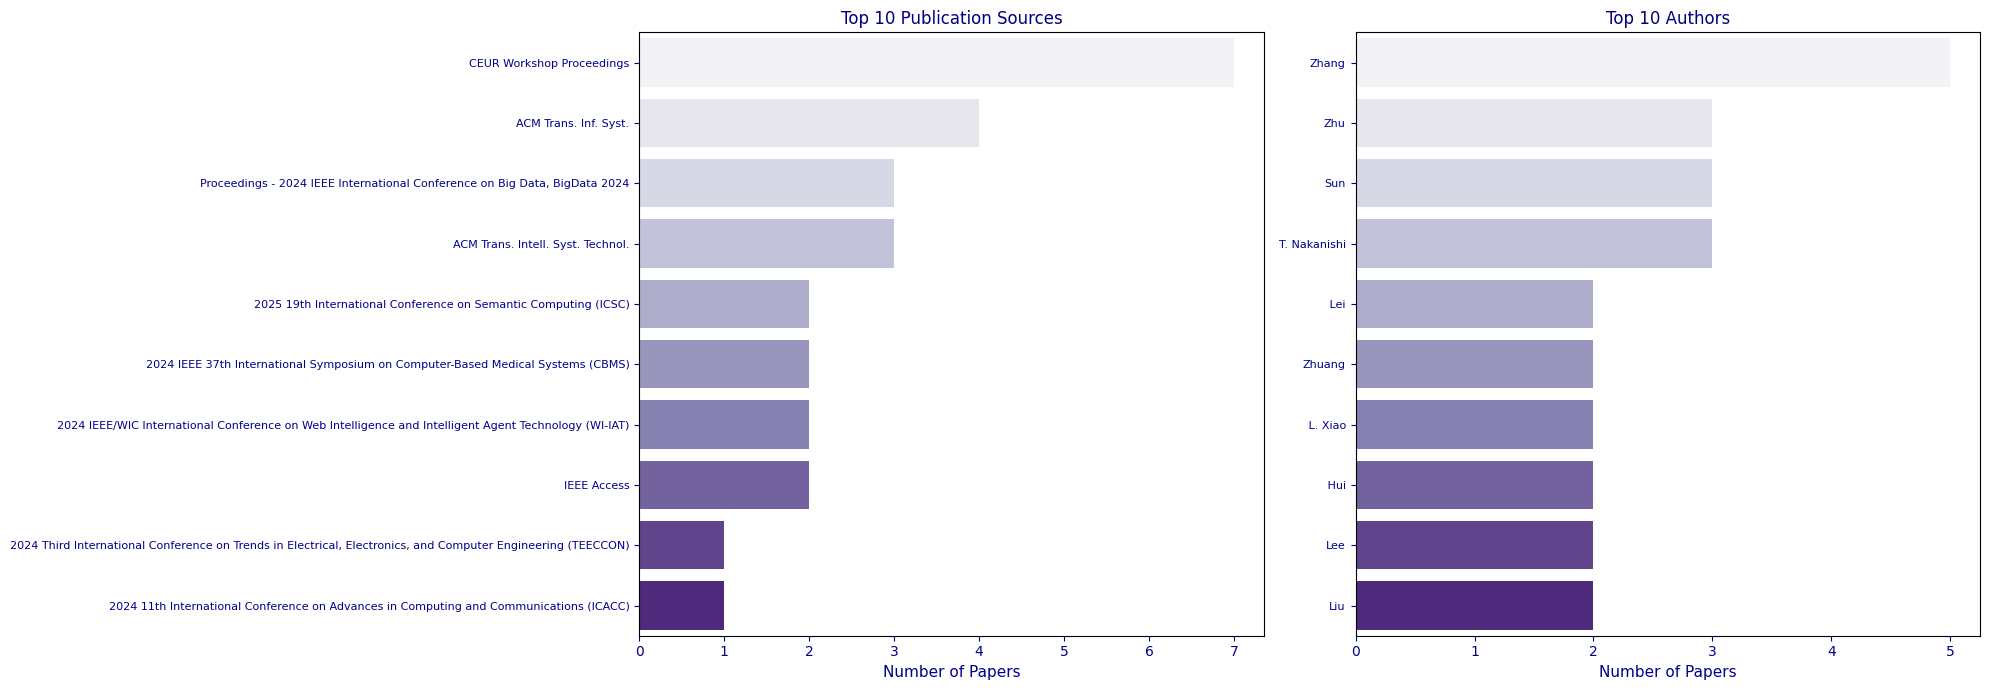

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Split authors
authors_split = df['Authors'].dropna().str.split(',|;| and ').explode()
top_authors = authors_split.value_counts().head(10)

# Top sources
top_sources = df['Source title'].value_counts().head(10)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(20, 7), sharex=False)

# Left: Top Publication Sources
sns.barplot(y=top_sources.index, x=top_sources.values, palette='Purples', ax=axes[0])
axes[0].set_title('Top 10 Publication Sources', fontsize=12, color='navy')
axes[0].set_xlabel('Number of Papers', fontsize=11, color='darkblue')
axes[0].set_ylabel('')
axes[0].tick_params(axis='x', colors='darkblue')
axes[0].tick_params(axis='y', colors='darkblue', labelsize=8)

# Right: Top Authors
sns.barplot(y=top_authors.index, x=top_authors.values, palette='Purples', ax=axes[1])
axes[1].set_title('Top 10 Authors', fontsize=12, color='navy')
axes[1].set_xlabel('Number of Papers', fontsize=11, color='darkblue')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', colors='darkblue')
axes[1].tick_params(axis='y', colors='darkblue', labelsize=8)

plt.tight_layout()
plt.show()


/tmp/ipython-input-64-560986654.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipython-input-64-560986654.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_yticklabels(
/tmp/ipython-input-64-560986654.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipython-input-64-560986654.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_yticklabels(


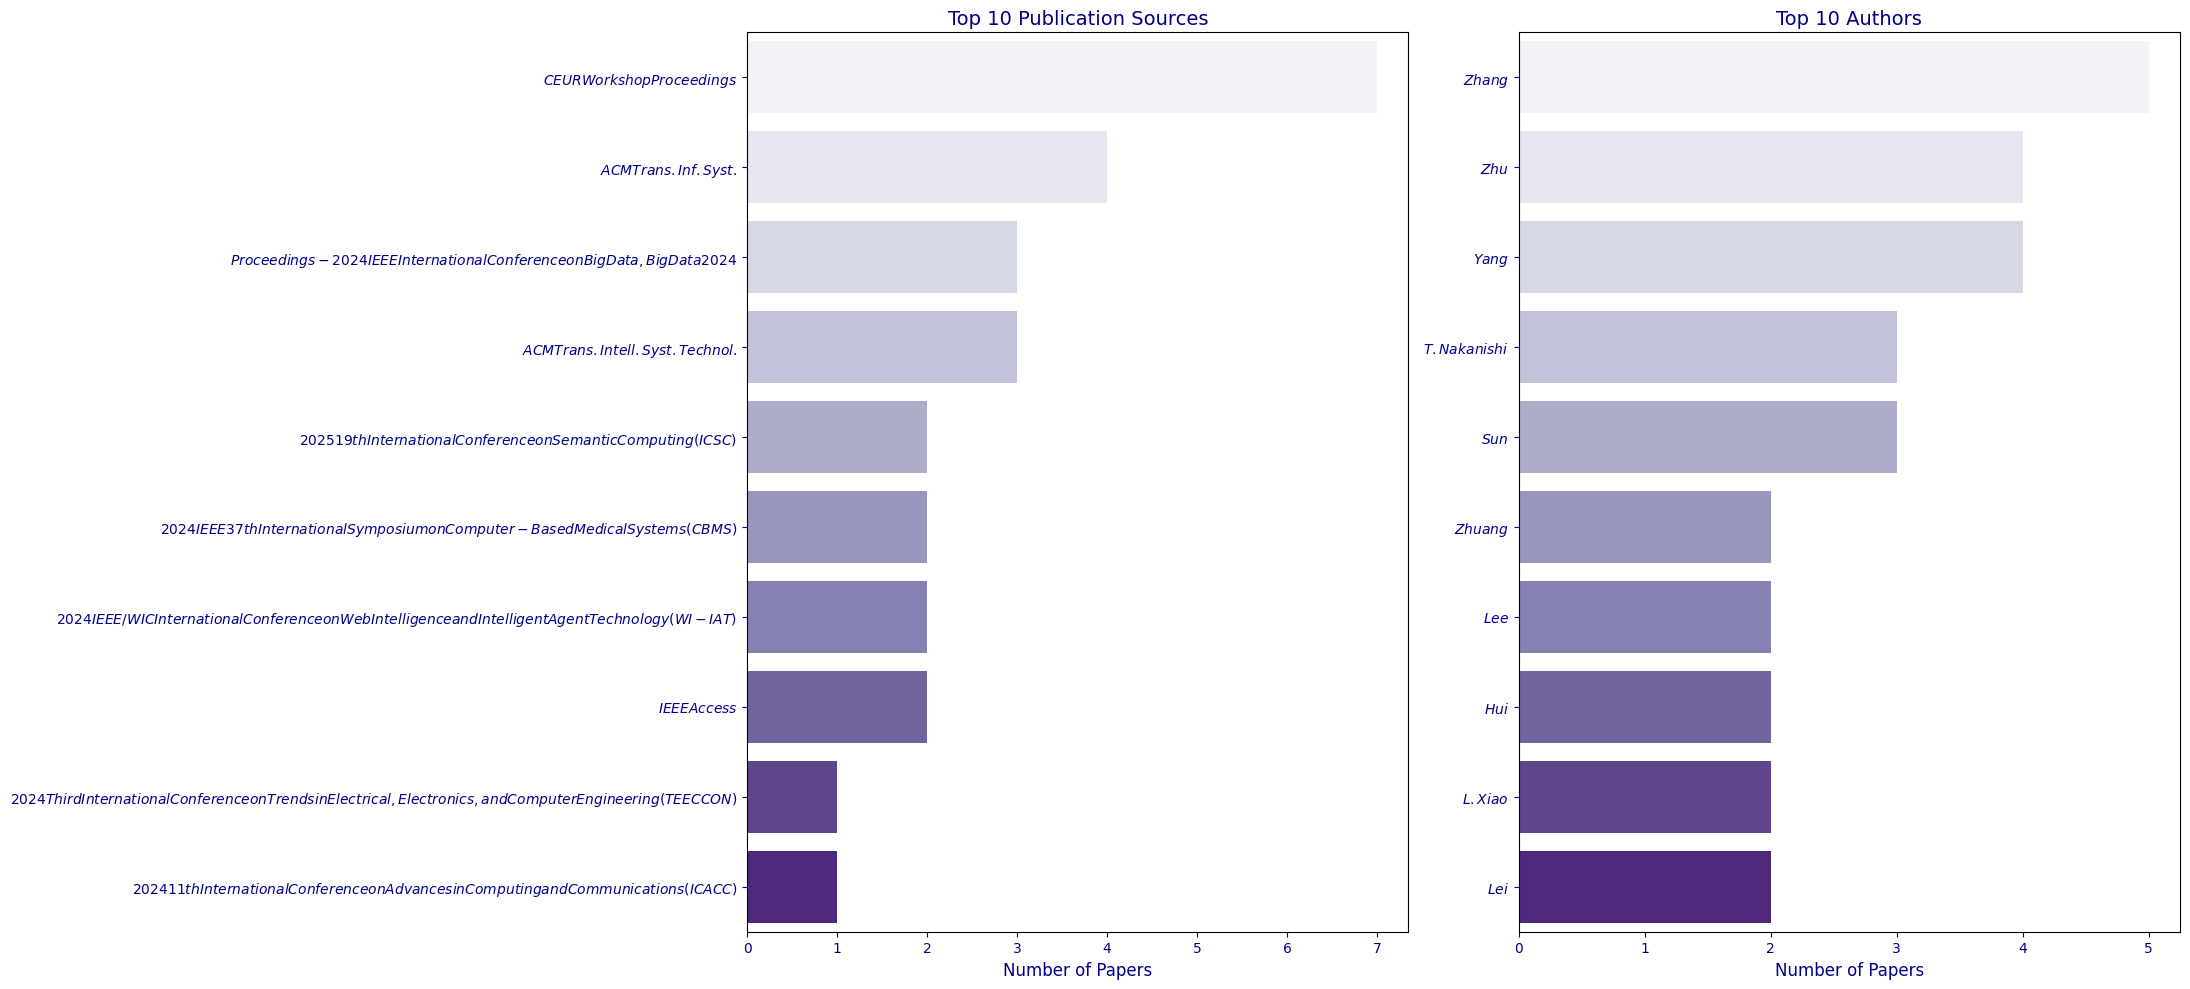

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocess authors
authors_split = df['Authors'].dropna().str.split(',|;| and ').explode()
authors_split = authors_split.str.strip() # + ' et al.'
top_authors = authors_split.value_counts().head(10)

# Top sources
top_sources = df['Source title'].value_counts().head(10)

# Create figure with more vertical space between bars
fig, axes = plt.subplots(1, 2, figsize=(22, 10), sharex=False)

# Left: Top Publication Sources
sns.barplot(
    y=top_sources.index,
    x=top_sources.values,
    palette='Purples',
    ax=axes[0],
    dodge=False
)
axes[0].set_title('Top 10 Publication Sources', fontsize=14, color='navy')
axes[0].set_xlabel('Number of Papers', fontsize=12, color='darkblue')
axes[0].set_ylabel('')
axes[0].tick_params(axis='x', colors='darkblue')
axes[0].tick_params(axis='y', colors='darkblue', labelsize=10)

# Italic ytick labels
axes[0].set_yticklabels(
    [f"$\\it{{{label}}}$" for label in top_sources.index],
    fontsize=10,
    color='darkblue'
)

# Right: Top Authors
sns.barplot(
    y=top_authors.index,
    x=top_authors.values,
    palette='Purples',
    ax=axes[1],
    dodge=False
)
axes[1].set_title('Top 10 Authors', fontsize=14, color='navy')
axes[1].set_xlabel('Number of Papers', fontsize=12, color='darkblue')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', colors='darkblue')
axes[1].tick_params(axis='y', colors='darkblue', labelsize=10)

# Italic ytick labels with "et al."
axes[1].set_yticklabels(
    [f"$\\it{{{label}}}$" for label in top_authors.index],
    fontsize=10,
    color='darkblue'
)

plt.tight_layout()
plt.show()


In [ ]:
figsize = (6,4)

In [ ]:
df.Year.value_counts()

,count
Year,
2024,48
2025,25
2023,3
2022,2


/tmp/ipython-input-38-1371641321.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Year', data=df, palette='BuPu')


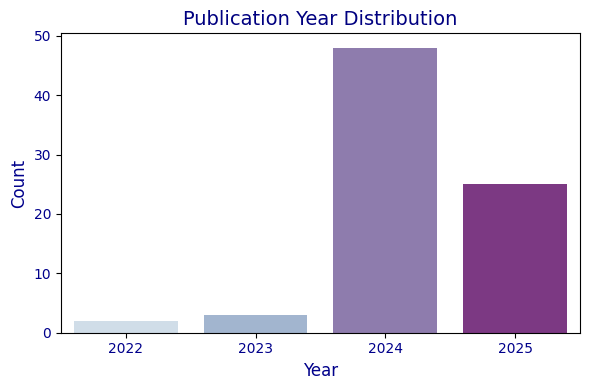

In [ ]:
plt.figure(figsize=figsize)
sns.countplot(x='Year', data=df, palette='BuPu')
plt.title('Publication Year Distribution', fontsize=14, color='navy')
plt.xlabel('Year', fontsize=12, color='darkblue')
plt.ylabel('Count', fontsize=12, color='darkblue')
plt.xticks(color='darkblue')
plt.yticks(color='darkblue')
plt.tight_layout()
plt.show()

/tmp/ipython-input-68-2938837858.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_sources.index, x=top_sources.values, palette='Purples')
/tmp/ipython-input-68-2938837858.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


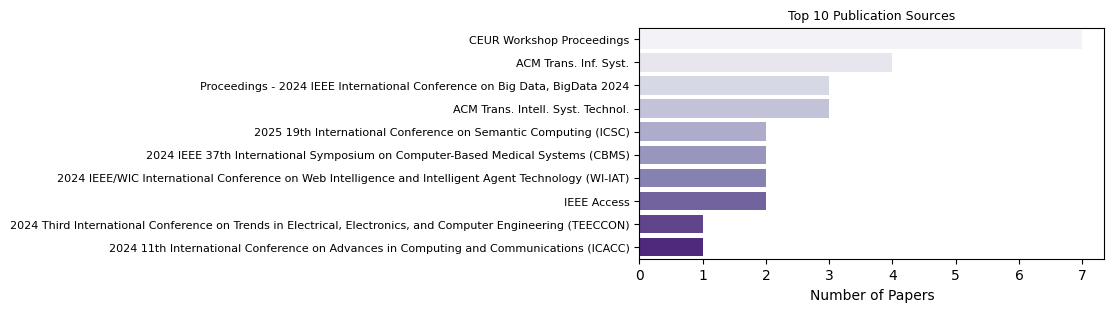

In [ ]:
top_sources = df['Source title'].value_counts().head(10)

plt.figure(figsize=(6, 3))
sns.barplot(y=top_sources.index, x=top_sources.values, palette='Purples')
plt.title('Top 10 Publication Sources', fontsize=9, color='black')
plt.xlabel('Number of Papers', fontsize=10, color='black')
plt.ylabel('', fontsize=12, color='black')
plt.xticks(color='black')
plt.yticks(color='black', fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
ranked_table = top_sources.reset_index()
ranked_table.columns = ['Publication Source', 'Number of Papers']
print(ranked_table.to_markdown())

import tabulate
print(tabulate.tabulate(ranked_table, headers='keys', tablefmt='github'))

|    | Publication Source                                                                                           |   Number of Papers |
|---:|:-------------------------------------------------------------------------------------------------------------|-------------------:|
|  0 | CEUR Workshop Proceedings                                                                                    |                  7 |
|  1 | ACM Trans. Inf. Syst.                                                                                        |                  4 |
|  2 | Proceedings - 2024 IEEE International Conference on Big Data, BigData 2024                                   |                  3 |
|  3 | ACM Trans. Intell. Syst. Technol.                                                                            |                  3 |
|  4 | 2025 19th International Conference on Semantic Computing (ICSC)                                              |                  2 |
|  5 | 2024 IEEE 37th Inter

/tmp/ipython-input-72-1965874619.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_authors.index, x=top_authors.values, palette='Purples')


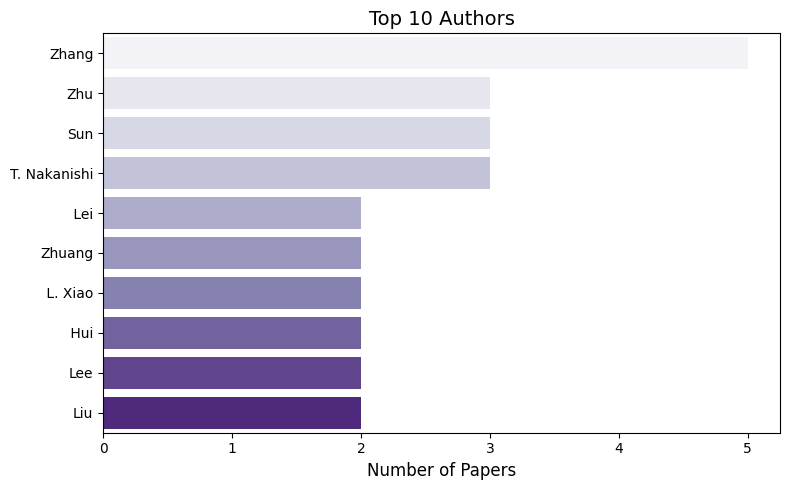

In [ ]:
# Split authors by separator (adjust if yours is different)
authors_split = df['Authors'].dropna().str.split(',|;| and ').explode()
top_authors = authors_split.value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(y=top_authors.index, x=top_authors.values, palette='Purples')
plt.title('Top 10 Authors', fontsize=14, color='black')
plt.xlabel('Number of Papers', fontsize=12, color='black')
plt.ylabel('', fontsize=12, color='black')
plt.xticks(color='black')
plt.yticks(color='black')
plt.tight_layout()
plt.show()

/tmp/ipython-input-71-163609615.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_keywords.index, x=top_keywords.values, palette='BuPu')


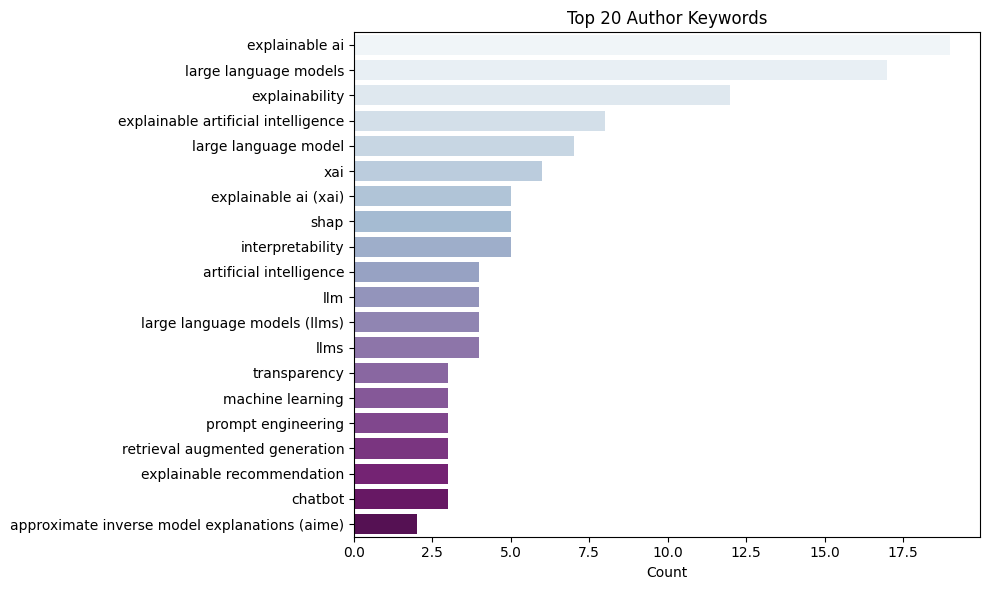

In [ ]:
# Split keywords (adjust separator if needed)
keywords_split = df['Author Keywords'].dropna().str.lower().str.split(';|,').explode()
keywords_split = keywords_split.str.strip()
top_keywords = keywords_split.value_counts().head(20)

plt.figure(figsize=(10, 6))
sns.barplot(y=top_keywords.index, x=top_keywords.values, palette='BuPu')
plt.title('Top 20 Author Keywords', fontsize=12, color='black')
plt.xlabel('Count', fontsize=10, color='black')
plt.ylabel('', fontsize=10, color='black')
plt.xticks(color='black', fontsize=10)
plt.yticks(color='black', fontsize=10)
plt.tight_layout()
plt.show()

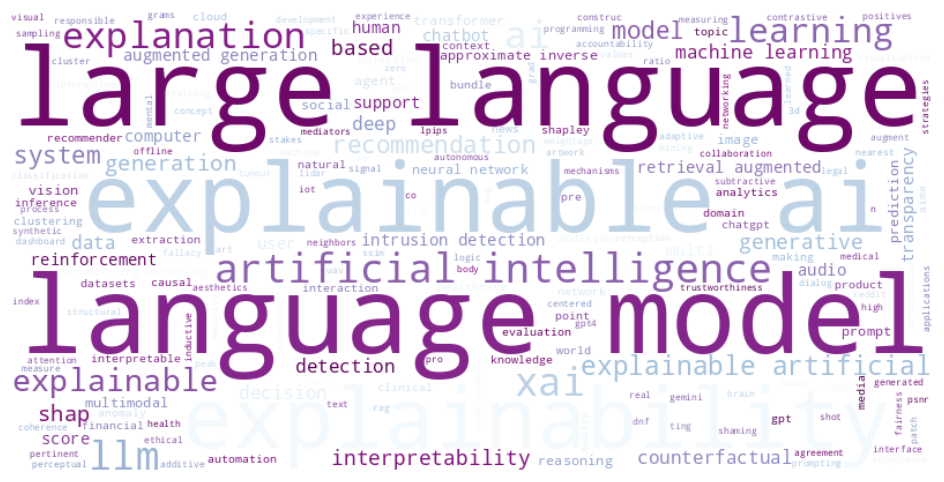

In [ ]:
all_keywords = ' '.join(keywords_split.dropna())
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='BuPu'
).generate(all_keywords)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
# plt.title('Author Keywords Word Cloud', fontsize=16, color='navy')
plt.show()